# Wine Quality (UCI): loading, inspection, cleaning and first visualizations

**Project question.** How does splitting the data by wine type (red / white) change cross-validation results, and which chemical measurements turn out to be the most important when ranked with permutation importance?

**This notebook covers the data-preparation stage only**:

1. Load both datasets (red and white)
2. Inspect them: `shape`, `info`, `isnull`, `describe`
3. Handle missing values
4. Drop unnecessary columns and duplicate rows
5. Reduce values to categories
6. Normalize the numeric features
7. Make a few simple, informative visualizations

**Data:** `winequality-red.csv` and `winequality-white.csv` from the UCI repository.

## 0. Setup

We import the libraries, fix the random seed (reproducibility) and define one colour per wine type, so that red is always red and white is always the same warm yellow in every figure.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.preprocessing import StandardScaler
from IPython.display import display

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# One colour per wine type, used consistently in all figures
COLORS = {"red": "#e34948", "white": "#eda100"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

print("python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)
print("scikit-learn:", sklearn.__version__)

python      : 3.13.18
numpy       : 2.5.3
pandas      : 3.0.5
matplotlib  : 3.10.8
seaborn     : 0.13.2
scikit-learn: 1.9.1


## 1. Load both datasets

The UCI files use a **semicolon** as the separator (`sep=";"`), which is why a default `pd.read_csv` would produce a single column. We check that both files have exactly the same columns, then add a `wine_type` column so that we can tell the wines apart after merging.

In [2]:
RED_PATH = Path("dataset/winequality-red.csv")
WHITE_PATH = Path("dataset/winequality-white.csv")

red = pd.read_csv(RED_PATH, sep=";")
white = pd.read_csv(WHITE_PATH, sep=";")

# Both files must describe the same variables, otherwise they cannot be merged
assert list(red.columns) == list(white.columns), "Red and white files have different columns"

red["wine_type"] = "red"
white["wine_type"] = "white"

print("Loaded successfully.")

Loaded successfully.


## 2. First look at the data

### 2.1 `shape`: how many rows and columns?

In [3]:
shape_table = pd.DataFrame(
    {"rows": [len(red), len(white), len(red) + len(white)],
     "columns": [red.shape[1], white.shape[1], red.shape[1]]},
    index=["red", "white", "total"],
)
shape_table

,rows,columns
red,1599,13
white,4898,13
total,6497,13


White wine has roughly three times more samples than red. This imbalance matters for the project: a model trained on the merged data is dominated by white wine, so "pooled" and "per-type" cross-validation can behave very differently.

### 2.2 `head`: a few raw rows

In [4]:
display(red.head(3))
display(white.head(3))

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,white
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,white
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,white


### 2.3 `info`: column types and non-null counts

`info()` tells us the data type of every column and how many values are present. We expect all 11 physico-chemical features to be floats, `quality` to be an integer, and no missing values.

In [5]:
print("=== RED ===")
red.info()
print()
print("=== WHITE ===")
white.info()

=== RED ===
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
 12  wine_type             1599 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 162.5 KB

=== WHITE ===
<class 'pandas.DataFrame'>
RangeIndex: 4898 entries

### 2.4 `isnull`: missing values per column

In [6]:
missing = pd.DataFrame({"red": red.isnull().sum(), "white": white.isnull().sum()})
missing["total"] = missing["red"] + missing["white"]
display(missing)
print("Total missing values:", int(missing["total"].sum()))

,red,white,total
fixed acidity,0,0,0
volatile acidity,0,0,0
citric acid,0,0,0
residual sugar,0,0,0
chlorides,0,0,0
free sulfur dioxide,0,0,0
total sulfur dioxide,0,0,0
density,0,0,0
pH,0,0,0
sulphates,0,0,0


Total missing values: 0


### 2.5 `describe`: summary statistics

We look at the count, mean, standard deviation, min / max and quartiles of every numeric column. We are looking for implausible values (negative concentrations, absurd maxima) and for very different scales between features, because that is what motivates the normalization step later.

In [7]:
print("=== RED ===")
display(red.describe().T.round(3))
print("=== WHITE ===")
display(white.describe().T.round(3))

=== RED ===


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


=== WHITE ===


,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.855,0.844,3.800,6.300,6.800,7.300,14.200
volatile acidity,4898.0,0.278,0.101,0.080,0.210,0.260,0.320,1.100
citric acid,4898.0,0.334,0.121,0.000,0.270,0.320,0.390,1.660
residual sugar,4898.0,6.391,5.072,0.600,1.700,5.200,9.900,65.800
chlorides,4898.0,0.046,0.022,0.009,0.036,0.043,0.050,0.346
free sulfur dioxide,4898.0,35.308,17.007,2.000,23.000,34.000,46.000,289.000
total sulfur dioxide,4898.0,138.361,42.498,9.000,108.000,134.000,167.000,440.000
density,4898.0,0.994,0.003,0.987,0.992,0.994,0.996,1.039
pH,4898.0,3.188,0.151,2.720,3.090,3.180,3.280,3.820
sulphates,4898.0,0.490,0.114,0.220,0.410,0.470,0.550,1.080


To see **how different the two wine types are**, we compare the feature means side by side (`white / red` ratio). Ratios far from 1 mean that the feature distinguishes the two types. This is the first hint of why the red / white split can matter for validation.

In [8]:
num_cols = red.select_dtypes("number").columns
compare = pd.DataFrame({"red_mean": red[num_cols].mean(), "white_mean": white[num_cols].mean()})
compare["white/red"] = compare["white_mean"] / compare["red_mean"]
display(compare.round(3))

,red_mean,white_mean,white/red
fixed acidity,8.320,6.855,0.824
volatile acidity,0.528,0.278,0.527
citric acid,0.271,0.334,1.233
residual sugar,2.539,6.391,2.517
chlorides,0.087,0.046,0.523
free sulfur dioxide,15.875,35.308,2.224
total sulfur dioxide,46.468,138.361,2.978
density,0.997,0.994,0.997
pH,3.311,3.188,0.963
sulphates,0.658,0.490,0.744


## 3. Merge into one DataFrame and handle missing values

We concatenate the two tables (`ignore_index=True` gives a clean 0..N-1 index). Then:

- every feature is forced to be numeric with `pd.to_numeric(errors="coerce")`, so any malformed text value turns into `NaN` instead of silently staying a string;
- if (and only if) there are missing feature values, they are filled with the **median of the same wine type** (the median is robust to outliers, and red and white wines have different typical values);
- rows with a missing target (`quality`) are dropped, because we never invent labels.

For this dataset the check finds nothing to fix, but the code is written so that it would handle the problem if it appeared.

In [9]:
df = pd.concat([red, white], ignore_index=True)

TARGET = "quality"
FEATURES = [c for c in df.columns if c not in (TARGET, "wine_type")]

# 1) Force numeric types; unparsable values become NaN
for col in FEATURES + [TARGET]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 2) Count missing values
n_missing = int(df.isnull().sum().sum())
print("Missing values before handling:", n_missing)

# 3) Handle them (only runs if something is missing)
if n_missing > 0:
    df = df.dropna(subset=[TARGET])  # never impute the target
    medians = df.groupby("wine_type")[FEATURES].transform("median")
    df[FEATURES] = df[FEATURES].fillna(medians)

print("Missing values after handling :", int(df.isnull().sum().sum()))
print("Merged shape:", df.shape)

Missing values before handling: 0
Missing values after handling : 0
Merged shape: (6497, 13)


> **Note on leakage.** Imputing with medians computed on the whole dataset is fine for exploration. In the modelling stage, imputation (and scaling) must go **inside a `Pipeline` that is fitted within each cross-validation fold**, otherwise information from the validation fold leaks into training.

## 4. Drop unnecessary columns and duplicate rows

### 4.1 Columns

A column is useless if it carries no information. We drop columns that are

- leftovers of an index (`Unnamed: 0`, `id`, `index`), or
- constant (only one unique value).

The raw UCI files contain neither, so normally nothing is dropped. We also **check for strongly correlated feature pairs, but deliberately do not drop them**: they are all real measurements, and removing one of them would change the answer to our research question. (Permutation importance is known to split the importance between correlated features, so we only keep this in mind for the interpretation later.)

In [10]:
index_like = [c for c in df.columns if c.lower().startswith("unnamed") or c.lower() in {"id", "index"}]
constant = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
to_drop = sorted(set(index_like + constant))

print("Columns dropped:", to_drop if to_drop else "none (all columns carry information)")
df = df.drop(columns=to_drop)
FEATURES = [c for c in df.columns if c not in (TARGET, "wine_type")]

# Report (but keep) strongly correlated feature pairs
corr_abs = df[FEATURES].corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
print("\nFeature pairs with |correlation| > 0.6 (kept on purpose):")
display(pairs[pairs > 0.6].round(3).to_frame("abs_corr"))

Columns dropped: none (all columns carry information)

Feature pairs with |correlation| > 0.6 (kept on purpose):


,,abs_corr
free sulfur dioxide,total sulfur dioxide,0.721
density,alcohol,0.687


### 4.2 Duplicate rows

The wine-quality files contain many exactly repeated rows. Identical rows are a problem for validation: after a random split, one copy can land in the training fold and the other in the validation fold, which makes the score look better than it really is (a form of **leakage**). We count them and drop all repeats, keeping the first occurrence.

In [11]:
dup_mask = df.duplicated(keep="first")
print("Duplicate rows by wine type:")
display(df.loc[dup_mask, "wine_type"].value_counts().rename("duplicates").to_frame())

rows_before = len(df)
df = df.drop_duplicates(keep="first").reset_index(drop=True)
print(f"Rows: {rows_before} -> {len(df)}  (removed {rows_before - len(df)})")
display(df["wine_type"].value_counts().rename("rows_after_dedup").to_frame())

Duplicate rows by wine type:


,duplicates
wine_type,
white,937
red,240


Rows: 6497 -> 5320  (removed 1177)


,rows_after_dedup
wine_type,
white,3961
red,1359


## 5. Reduce values to categories

Two categorical variables are useful:

- **`wine_type`** is stored as a string; we convert it to a pandas `category` dtype (smaller, and explicit about the allowed values).
- **`quality`** is a score from 3 to 9, and the extreme scores are very rare. We bin it into three **ordered** classes: `low` (3-4), `medium` (5-6) and `high` (7-9). The original numeric `quality` column is kept as well, so that we can later choose between regression and classification.

In [12]:
df["wine_type"] = pd.Categorical(df["wine_type"], categories=["red", "white"])

quality_bins = [0, 4, 6, 10]  # intervals are (0,4], (4,6], (6,10]
quality_labels = ["low (3-4)", "medium (5-6)", "high (7-9)"]
df["quality_category"] = pd.cut(df[TARGET], bins=quality_bins, labels=quality_labels, ordered=True)

print("Original quality scores:")
display(df[TARGET].value_counts().sort_index().to_frame("count").T)

print("Quality categories by wine type (row-normalized shares):")
display(pd.crosstab(df["wine_type"], df["quality_category"], normalize="index").round(3))
print("Counts:")
display(pd.crosstab(df["wine_type"], df["quality_category"]))

Original quality scores:


quality,3,4,5,6,7,8,9
count,30,206,1752,2323,856,148,5


Quality categories by wine type (row-normalized shares):


quality_category,low (3-4),medium (5-6),high (7-9)
wine_type,,,
red,0.046,0.818,0.135
white,0.044,0.748,0.208


Counts:


quality_category,low (3-4),medium (5-6),high (7-9)
wine_type,,,
red,63,1112,184
white,173,2963,825


Most wines are `medium` quality, and the `low` class is very small (especially for white wine). Keep this in mind: with such imbalance, plain accuracy would be a misleading metric later.

## 6. Normalize the numeric features

The features live on very different scales (for example `total sulfur dioxide` is in the tens or hundreds, while `chlorides` is around 0.05). Distance-based and linear models, and the comparison of features in plots, need comparable scales.

We use **standardization** (`StandardScaler`): `z = (x - mean) / std`, so every feature ends up with mean 0 and standard deviation 1. We store the result in a **separate DataFrame** `df_scaled`, so that `df` keeps the original, interpretable units.

> **Important.** Here the scaler is fitted on the whole dataset, which is acceptable only for EDA and plotting. In the modelling stage, the scaler must be a step inside the `Pipeline`, fitted on the training part of each fold only.

Standardization changes the scale, **not the shape**: skewed features stay skewed. We print the skewness to see which features are strongly skewed (a log-transform could be considered later).

In [13]:
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[FEATURES] = scaler.fit_transform(df[FEATURES])

print("Before scaling (original units):")
display(df[FEATURES].describe().loc[["mean", "std", "min", "max"]].T.round(3))

print("After scaling (mean ~ 0, std ~ 1):")
display(df_scaled[FEATURES].describe().loc[["mean", "std", "min", "max"]].T.round(3))

print("Skewness of the features (|skew| > 1 means strongly skewed):")
display(df[FEATURES].skew().sort_values(ascending=False).round(2).to_frame("skew").T)

Before scaling (original units):


,mean,std,min,max
fixed acidity,7.215,1.320,3.800,15.900
volatile acidity,0.344,0.168,0.080,1.580
citric acid,0.318,0.147,0.000,1.660
residual sugar,5.048,4.500,0.600,65.800
chlorides,0.057,0.037,0.009,0.611
free sulfur dioxide,30.037,17.805,1.000,289.000
total sulfur dioxide,114.109,56.774,6.000,440.000
density,0.995,0.003,0.987,1.039
pH,3.225,0.160,2.720,4.010
sulphates,0.533,0.150,0.220,2.000


After scaling (mean ~ 0, std ~ 1):


,mean,std,min,max
fixed acidity,0.0,1.0,-2.588,6.582
volatile acidity,-0.0,1.0,-1.570,7.346
citric acid,0.0,1.0,-2.165,9.117
residual sugar,0.0,1.0,-0.989,13.501
chlorides,0.0,1.0,-1.294,15.038
free sulfur dioxide,0.0,1.0,-1.631,14.546
total sulfur dioxide,-0.0,1.0,-1.904,5.741
density,0.0,1.0,-2.504,14.989
pH,0.0,1.0,-3.147,4.897
sulphates,-0.0,1.0,-2.093,9.795


Skewness of the features (|skew| > 1 means strongly skewed):


,chlorides,sulphates,residual sugar,fixed acidity,volatile acidity,free sulfur dioxide,density,alcohol,citric acid,pH,total sulfur dioxide
skew,5.34,1.81,1.71,1.65,1.5,1.36,0.67,0.55,0.48,0.39,0.06


## 7. Visualizations

Four simple figures, each answering one question that matters for the project.

### 7.1 How many wines of each type, and how is quality distributed within each type?

We show **shares within each type** (not raw counts) for the quality scores, because the two types have very different sizes and raw counts would hide the comparison.

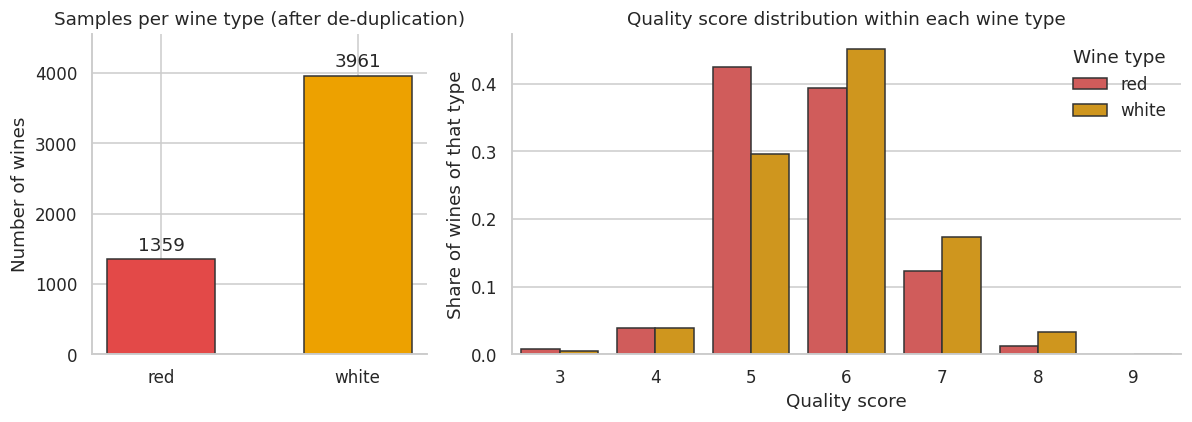

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 2]})

# (a) number of rows per wine type
counts = df["wine_type"].value_counts().reindex(["red", "white"])
bars = axes[0].bar(counts.index, counts.values, color=[COLORS[k] for k in counts.index],
                   edgecolor="#333333", width=0.55)
axes[0].bar_label(bars, padding=3)
axes[0].set_ylim(0, counts.max() * 1.15)  # headroom so the label is not clipped
axes[0].set_title("Samples per wine type (after de-duplication)")
axes[0].set_ylabel("Number of wines")

# (b) share of each quality score inside each type
share = (df.groupby("wine_type", observed=True)[TARGET]
           .value_counts(normalize=True).rename("share").reset_index())
sns.barplot(data=share, x=TARGET, y="share", hue="wine_type", hue_order=["red", "white"],
            palette=COLORS, edgecolor="#333333", ax=axes[1])
axes[1].set_title("Quality score distribution within each wine type")
axes[1].set_xlabel("Quality score")
axes[1].set_ylabel("Share of wines of that type")
axes[1].legend(title="Wine type", frameon=False)

plt.tight_layout()
fig.savefig(FIG_DIR / "01_type_and_quality_distribution.png", bbox_inches="tight")
plt.show()

**How to read it:** the left panel shows the size imbalance between red and white. The right panel shows that both types concentrate on scores 5-6, and that very high or very low scores are rare, so the target is imbalanced.

### 7.2 Do red and white wines differ chemically?

Boxplots of the **standardized** features, split by wine type. Because all features are on the same scale, they can share one axis. If the red and white boxes are clearly shifted for a feature, that feature separates the two types, and a pooled model could partly "learn the wine type" instead of "learn quality".

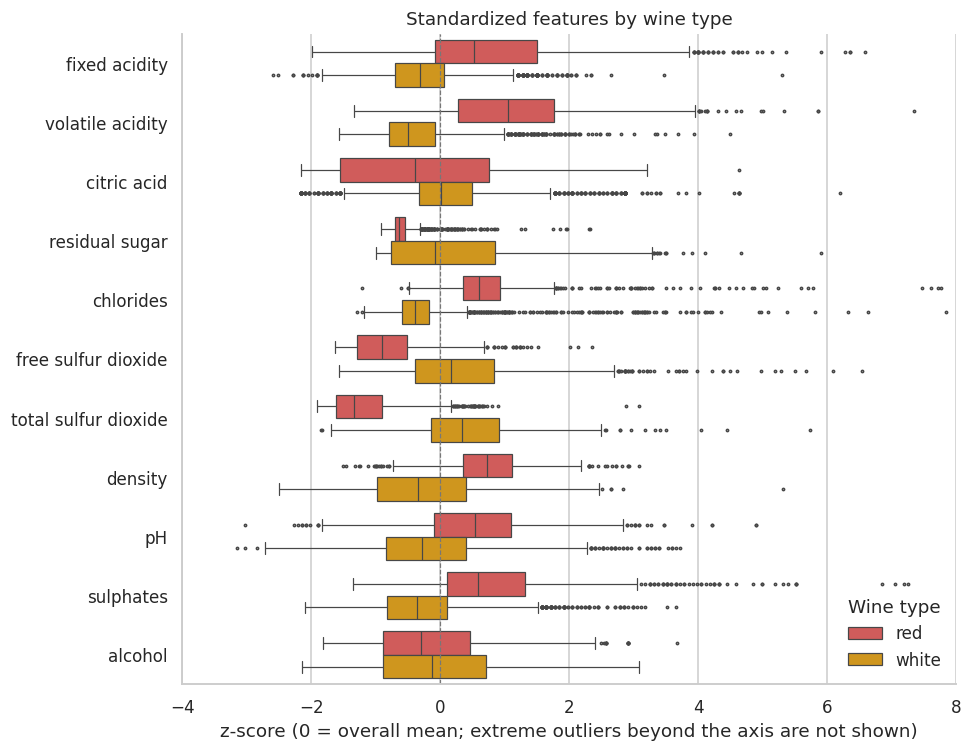

In [15]:
long = df_scaled.melt(id_vars="wine_type", value_vars=FEATURES, var_name="feature", value_name="z_score")

fig, ax = plt.subplots(figsize=(9, 7))
sns.boxplot(data=long, x="z_score", y="feature", hue="wine_type", hue_order=["red", "white"],
            palette=COLORS, fliersize=1.5, linewidth=0.8, ax=ax)
ax.axvline(0, color="#777777", lw=0.8, ls="--")
ax.set_xlim(-4, 8)  # a few extreme outliers (z > 8) are cut off so the boxes stay readable
ax.set_title("Standardized features by wine type")
ax.set_xlabel("z-score (0 = overall mean; extreme outliers beyond the axis are not shown)")
ax.set_ylabel("")
ax.legend(title="Wine type", frameon=False, loc="lower right")

plt.tight_layout()
fig.savefig(FIG_DIR / "02_features_by_wine_type.png", bbox_inches="tight")
plt.show()

**How to read it:** the box shows the middle 50% of values, the line inside is the median, and the dots are outliers (the axis is cut at z = 8, so a few extreme outliers are not shown). Features such as `total sulfur dioxide`, `residual sugar`, `volatile acidity` and `chlorides` are clearly shifted between the two types, which means the types are chemically distinguishable.

### 7.3 Which features are related to each other and to quality?

Correlation heatmaps (Pearson) for red and white separately, including `quality`. Red means positive and blue means negative correlation. We use the same colour scale in both panels so that they can be compared directly.

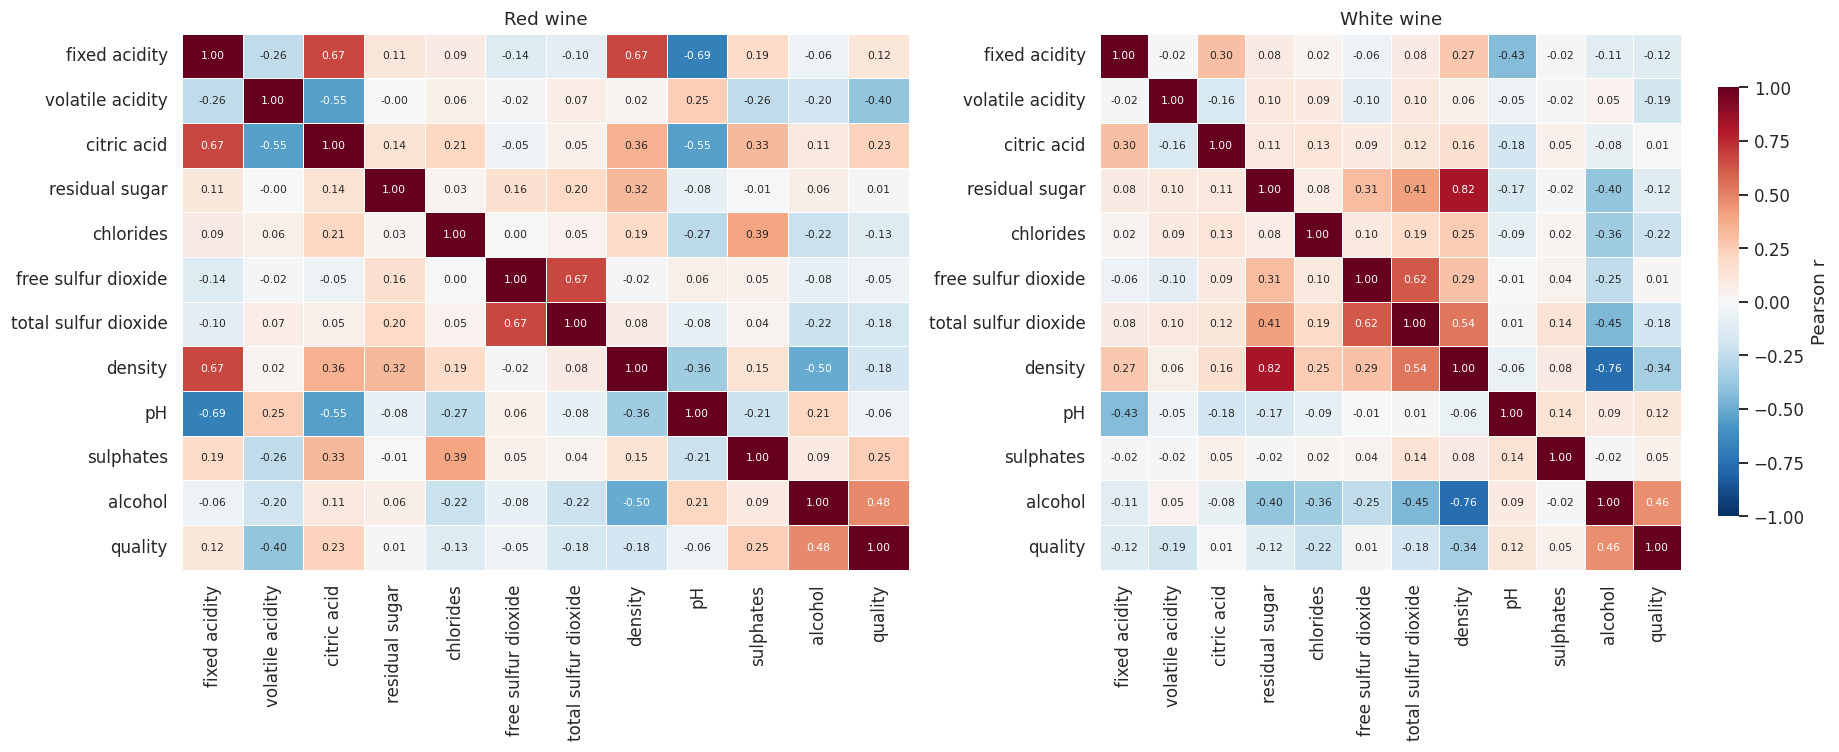

In [16]:
cols = FEATURES + [TARGET]
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

for ax, wtype in zip(axes, ["red", "white"]):
    c = df.loc[df["wine_type"] == wtype, cols].corr()
    sns.heatmap(c, ax=ax, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
                annot_kws={"size": 7}, linewidths=0.5, linecolor="white",
                cbar=(wtype == "white"), cbar_kws={"shrink": 0.8, "label": "Pearson r"})
    ax.set_title(f"{wtype.capitalize()} wine")

plt.tight_layout()
fig.savefig(FIG_DIR / "03_correlation_heatmaps.png", bbox_inches="tight")
plt.show()

**How to read it:** look at the last row (`quality`) to see which single features move together with quality, and at the cells between features to find redundant pairs (for example `density` with `alcohol` and `residual sugar`). Compare the two panels: if the same pair has a different sign or strength in red and in white, a single pooled model has to compromise between two different relationships.

### 7.4 How do the two most quality-related features behave across quality scores?

We automatically pick the two features with the highest absolute correlation with `quality` (on the merged data) and show their distribution for every quality score, separately for each wine type.

Top-2 features by |corr| with quality: ['alcohol', 'density']


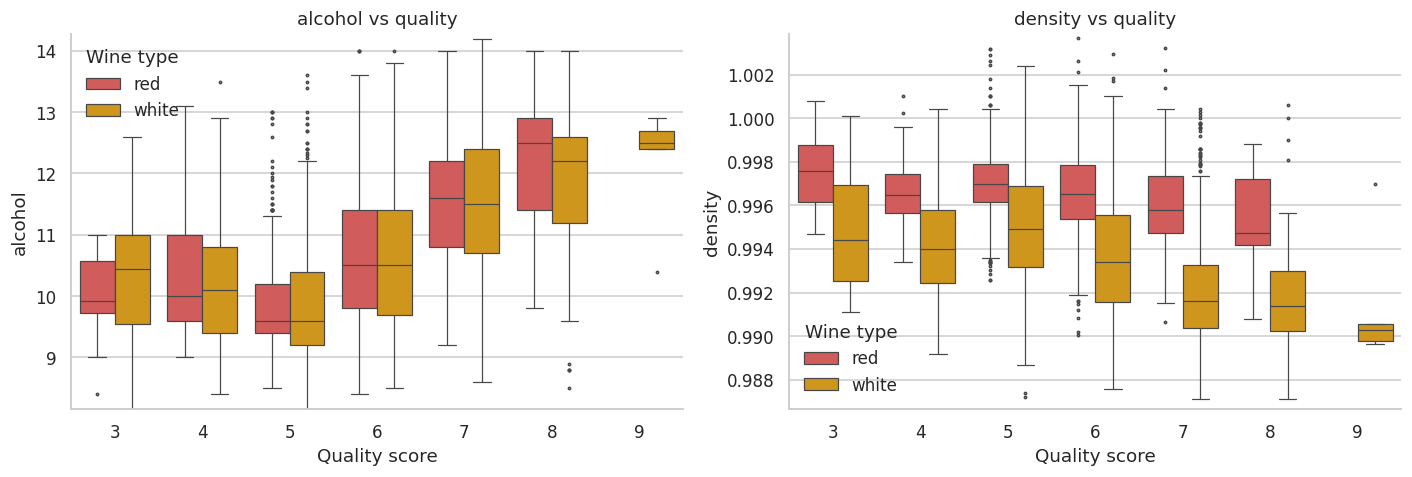

In [17]:
top2 = df[FEATURES].corrwith(df[TARGET]).abs().sort_values(ascending=False).index[:2].tolist()
print("Top-2 features by |corr| with quality:", top2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, feat in zip(axes, top2):
    sns.boxplot(data=df, x=TARGET, y=feat, hue="wine_type", hue_order=["red", "white"],
                palette=COLORS, fliersize=1.5, linewidth=0.8, ax=ax)
    lo, hi = df[feat].quantile(0.001), df[feat].quantile(0.999)
    pad = 0.05 * (hi - lo)
    ax.set_ylim(lo - pad, hi + pad)  # ignore a few extreme outliers so the boxes stay readable
    ax.set_title(f"{feat} vs quality")
    ax.set_xlabel("Quality score")
    ax.legend(title="Wine type", frameon=False)

plt.tight_layout()
fig.savefig(FIG_DIR / "04_top_features_vs_quality.png", bbox_inches="tight")
plt.show()

**How to read it:** if the boxes trend upward or downward as the quality score grows, the feature carries signal about quality. If the red and white boxes follow different trends, the relationship depends on the wine type, which is exactly the situation where splitting by type can change the cross-validation result.

## 8. Save the cleaned data

We save the cleaned, **un-scaled** table (original units, with the category columns). The scaled copy is not saved on purpose: scaling must be re-done inside the cross-validation pipeline to avoid leakage.

In [18]:
OUT_PATH = Path("dataset/wine_clean.csv")
df.to_csv(OUT_PATH, index=False)

print(f"Saved {OUT_PATH} with shape {df.shape}")
print("Columns:", list(df.columns))
display(df.head())

Saved dataset/wine_clean.csv with shape (5320, 14)
Columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'wine_type', 'quality_category']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type,quality_category
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red,medium (5-6)
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red,medium (5-6)
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red,medium (5-6)
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red,medium (5-6)
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,red,medium (5-6)


## Summary of what was done and what comes next

- Loaded the red and white files (semicolon-separated) and merged them with a `wine_type` column.
- Inspected shape, dtypes, missing values and summary statistics. No missing values were found.
- Removed exact duplicate rows to prevent leakage between cross-validation folds. No index-like or constant columns existed, and the correlated features were kept on purpose.
- Created `quality_category` (low / medium / high) and the categorical `wine_type`.
- Standardized the features in a separate copy for exploration only.